## Predicting Crop Yield

> The clean table generated in the `marts` stage has historical data that cannot tell a programme officer what yield to expect from a specific farm in a given season. Additionally, the data in the clean table cannot tell us which factors drive crop yield. This stage trains a model to predict crop yield, tests it on unseen data, and identifies the factors that have the largest impact on crop yield.

> The model reads from `marts.yield_dataset` and its predictions are written back to the database. **Steps followed:**

1.  Load the usable rows and select relevant features.
1.   **Train-test split:** Split dataset by time: train on 2019 to 2022 data and test on 2023 to 2024 data.
1.   Compare four models using cross-validation on the training data only: a simple baseline, linear regression, random forest and gradient boosting.
2.   Evaluate the best performing model once on the test data.
2.   Explain the results: which features matter, and what shape the rainfall and fertilizer effects take.
1.   Save the model and write the predictions back to the DuckDB database.













### Establish connections.

In [19]:
from pathlib import Path
from google.colab import drive
import shutil, sys
import duckdb
import joblib

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Mount Google Drive
drive.mount("/content/drive")

# Define paths
drive_db = Path("/content/drive/MyDrive/Agriculture_ELT/data/agri.duckdb")
db_path = Path("/content/agri.duckdb")

# Load the latest saved database from Drive
assert drive_db.exists(), "Database not found in Google Drive"

if "conn" in globals():
    conn.close()

if db_path.exists():
    db_path.unlink()

shutil.copy(drive_db, db_path)

# Connect to db
conn = duckdb.connect(str(db_path))

print("\nDatabase loaded successfully.\n")

conn.sql("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema == 'marts'
    ORDER BY table_name
""").df()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Database loaded successfully.



,table_name
0,county_season_summary
1,planting_base
2,planting_inputs
3,planting_weather
4,yield_dataset


### Load Modeling Data

> Only rows that are flagged `True` in `use_for_modeling` column; the **relevant features** include:
*   Weather-related features during the growing period: total rainfall, rain days, longest dry spell, & average temperatures.
*   Inputs per acre: fertilizer, manure, & pesticides.
*   Farm & crop info: crop, county, soil type, irrigation, certified seed, farm size, planted area, season type (long or short rains)

> The following info is **left out** from the model:

*   **IDs**: the model might memorize farm_ids and planting_ids.
*   **Season_year**: The model might fail to generalize to future years.











In [20]:
data = conn.sql("""
    SELECT planting_id, season_year, yield_kg_per_acre,
           crop, county, soil_type, season_type,
           irrigated, certified_seed, used_manure, used_pesticide,
           size_acres, area_planted_acres,
           season_rain_mm, rain_days, max_dry_spell_days, mean_tmax_c, mean_tmin_c,
           fertilizer_kg_per_acre, n_fertilizer_applications,
           manure_kg_per_acre, pesticide_litres_per_acre
    FROM marts.yield_dataset
    WHERE use_for_modelling
""").df()

# Cols flagged as True/False to be converted as 1.0/0.0; missing records to appear as NaN.
flag_cols = ['irrigated', 'certified_seed', 'used_manure', 'used_pesticide']
for col in flag_cols:
  data[col] = data[col].map({True: 1.0, False: 0.0})

# Define features (both categorical and numerical features) and target
cat_cols = ["crop", "county", "soil_type", "season_type"]
num_cols = ["size_acres", "area_planted_acres", "season_rain_mm", "rain_days", "max_dry_spell_days",
            "mean_tmax_c", "mean_tmin_c", "fertilizer_kg_per_acre", "n_fertilizer_applications",
            "manure_kg_per_acre", "pesticide_litres_per_acre"]
features = cat_cols + flag_cols + num_cols
target = "yield_kg_per_acre"

# Magnitude of the data that is ideal for modeling
print(f"{len(data):,} rows, {len(features)} features")
# Missing values
data[features + [target]].isna().sum().loc[lambda s: s > 0].to_frame("missing_values")

4,451 rows, 19 features


,missing_values
soil_type,190
irrigated,119
certified_seed,272
size_acres,32


### Train-test split by time

> Data from 2019 to '22 is used for training and model selection. Seasons '23 and '24 are held back as the test set and used once, at the end. A random split would mix seasons together, and the model could learn each season's weather from its neighbours in the data.

> Missing values are filled inside the model pipeline, using only training data. If we filled them before splitting, information from the test set would leak into training.



In [21]:
# Train test split by time
train = data[data['season_year'] <= 2022]
test = data[data['season_year'] >= 2023]

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

print("Features dimensions:", X_train.shape, X_test.shape)
print("Target dimensions:", y_train.shape, y_test.shape)

Features dimensions: (2996, 19) (1455, 19)
Target dimensions: (2996,) (1455,)


### Define the Models

> All four models share the same preprocessing steps: fill missing numbers with the training median, fill missing categories with "unknown", and one-hot encode the categories. Additionally, linear regression also gets the numerical cols scaled.

*    **Baseline - crop median:** Predicts the typical yield for a crop. Other models are expected to beat the baseline.

*   **Ridge regression:**  A simple linear model. It can't capture the ideal rainfall values, so we expect it to struggle.
*   **Random forest:**  Many decision trees averaged together. Handles curves and interactions.
*   **Gradient boosting:** Decision trees built one after another, each correcting the last. Expected to be the strongest model.




In [22]:
 # Import libraries
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [23]:
# Define preprocessor
def preprocessor(scale=False):
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols + flag_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])

# Define baseline class
class CropMedianBaseline(BaseEstimator, RegressorMixin):
    """Predicts the median training yield for each crop."""
    def fit(self, X, y):
        self.medians_ = pd.Series(np.asarray(y), index=X["crop"].values).groupby(level=0).median()
        self.overall_ = float(np.median(y))
        return self

    def predict(self, X):
        return X["crop"].map(self.medians_).fillna(self.overall_).to_numpy()

# Define models: ridge regressor, random forest, gradient boosting regressor
models = {
    "Baseline: crop median": CropMedianBaseline(),
    "Ridge regression": Pipeline([("prep", preprocessor(scale=True)), ("model", Ridge(alpha=1.0))]),
    "Random forest": Pipeline([("prep", preprocessor()),
                               ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                                               random_state=18, n_jobs=-1))]),
    "Gradient boosting": Pipeline([("prep", preprocessor()),
                                   ("model", HistGradientBoostingRegressor(random_state=18))]),
}
list(models)

['Baseline: crop median',
 'Ridge regression',
 'Random forest',
 'Gradient boosting']

### Compare Models with Cross Validation

> Each model is trained and scored five times on different slices of the training data. The two measures used for model evaluation are:

*   **MAE (mean absolute error):** the average miss, in kg per acre. Lower is better.
*   **R²:** the share of the variation in yield the model explains. 1 is perfect, 0 is no better than guessing the average.



In [24]:
# Cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model in models.items():
    result = cross_validate(model, X_train, y_train, cv=cv,
                         scoring=("neg_mean_absolute_error", "r2"), n_jobs=1)
    rows.append({"model": name,
                 "cv_mae_kg_per_acre": -result["test_neg_mean_absolute_error"].mean(),
                 "cv_r2": result["test_r2"].mean()})

cv_results = pd.DataFrame(rows).set_index("model").round(3)
best_name = cv_results["cv_mae_kg_per_acre"].idxmin()
print("Best model by cross-validated MAE:", best_name)
cv_results

Best model by cross-validated MAE: Gradient boosting


,cv_mae_kg_per_acre,cv_r2
model,,
Baseline: crop median,217.390,0.441
Ridge regression,188.155,0.578
Random forest,147.680,0.678
Gradient boosting,145.433,0.685


### Evaluation on Test Data

> Every model is refitted on the training data and evauated once on test data (2023 and 2024).



In [25]:
def score(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "R2": r2_score(y_true, y_pred)}

fitted, test_rows = {}, []
for name, model in models.items():
    fitted[name] = model.fit(X_train, y_train)
    test_rows.append({"model": name, **score(y_test, fitted[name].predict(X_test))})

test_results = pd.DataFrame(test_rows).set_index("model").round(3)
test_results

,MAE,RMSE,R2
model,,,
Baseline: crop median,213.307,304.666,0.457
Ridge regression,196.112,273.563,0.563
Random forest,149.323,230.391,0.690
Gradient boosting,146.983,227.706,0.697


In [26]:
# Pick best model
best_model = fitted[best_name]
pred_test = best_model.predict(X_test)

# Base model performance
base = test_results.loc["Baseline: crop median", "MAE"]
# Best model performance
best = test_results.loc[best_name, "MAE"]
print(f"{best_name}: average miss of {best:.0f} kg/acre on unseen seasons "
      f"({best / y_test.mean():.0%} of the average yield), "
      f"{1 - best / base:.0%} lower than the crop-median baseline.")

Gradient boosting: average miss of 147 kg/acre on unseen seasons (23% of the average yield), 31% lower than the crop-median baseline.


### Accuracy per Crop

> Overall R² can hide weak spots, because crops have very different yield levels (beans around 250 kg/acre, maize and wheat above 800). Here is the best model's performance within each crop.



In [27]:
# Scoring by crops
by_crop = []
for crop, grp in test.assign(pred=pred_test).groupby("crop"):
    by_crop.append({"crop": crop, "n_test": len(grp),
                    "mean_actual": grp[target].mean(),
                    "MAE": mean_absolute_error(grp[target], grp["pred"]),
                    "MAE_pct_of_mean": mean_absolute_error(grp[target], grp["pred"]) / grp[target].mean(),
                    "R2_within_crop": r2_score(grp[target], grp["pred"])})
pd.DataFrame(by_crop).set_index("crop").round(2)

,n_test,mean_actual,MAE,MAE_pct_of_mean,R2_within_crop
crop,,,,,
beans,401,266.14,62.50,0.23,0.44
maize,723,860.70,193.14,0.22,0.46
sorghum,169,356.54,71.32,0.20,0.57
wheat,162,923.15,229.03,0.25,0.27


## Visualizations

### Predicted vs Actual

> Each dot is one planting in the test seasons. Dots on the diagonal line are perfect predictions.



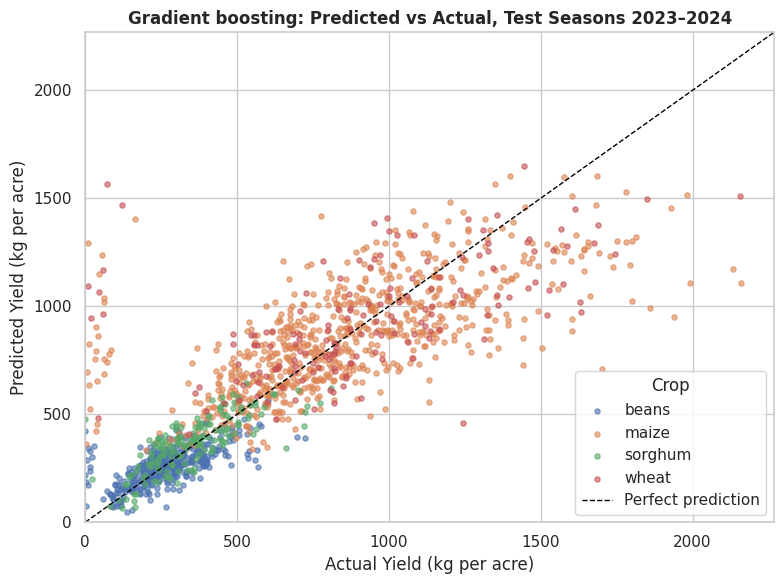

In [28]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(8, 6))

# Combine predictions with the test dataset
plot_data = test.copy()
plot_data["pred"] = pred_test

# Plot actual vs predicted yield for each crop
for crop, grp in plot_data.groupby("crop"):
    ax.scatter(
        grp[target],
        grp["pred"],
        s=14,
        alpha=0.6,
        label=crop
    )

# Calculate common axis limits
max_val = max(
    plot_data[target].max(),
    plot_data["pred"].max()
)

lim = [0, max_val * 1.05]

# Perfect prediction reference line
ax.plot(lim, lim, color="black", lw=1, ls="--", label="Perfect prediction")

# Configure axes and title
ax.set(
    xlim=lim,
    ylim=lim,
    xlabel="Actual Yield (kg per acre)",
    ylabel="Predicted Yield (kg per acre)"
)

ax.set_title(
    f"{best_name}: Predicted vs Actual, Test Seasons 2023–2024",
    fontweight="bold"
)

ax.legend(title="Crop", loc='lower right')
plt.tight_layout()
plt.show()

### Which Features Drive Yield?

> **Permutation importance** shuffles one feature at a time on the test set and measures how much the model's error gets worse. A big increase means the model relies heavily on that feature.


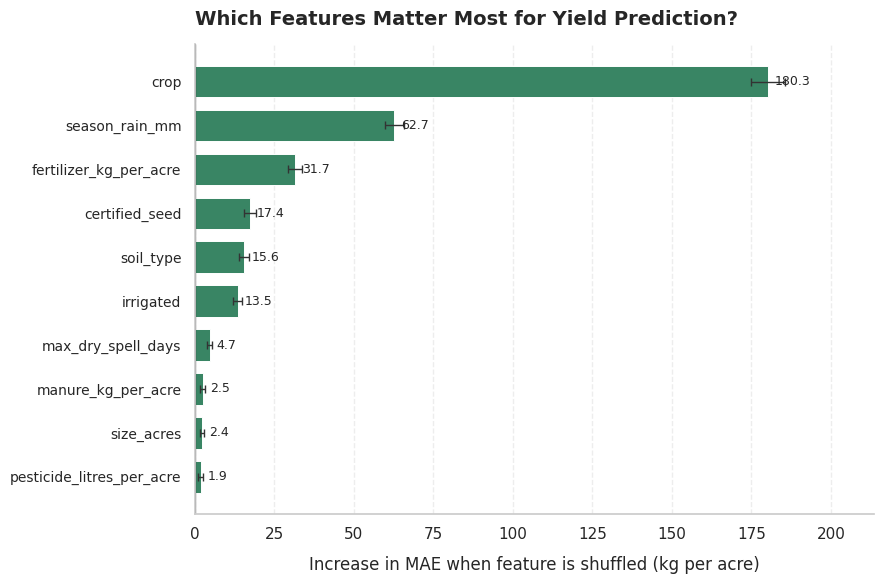

,MAE_increase_kg_per_acre,permutation_std
feature,,
crop,180.30,5.40
season_rain_mm,62.75,2.92
fertilizer_kg_per_acre,31.67,2.18
certified_seed,17.38,1.83
soil_type,15.63,1.59
irrigated,13.47,1.41
max_dry_spell_days,4.66,0.81
manure_kg_per_acre,2.54,0.73


In [33]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
imp = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Create a summary table
importance_df = pd.DataFrame({
    "feature": features,
    "importance": imp.importances_mean,
    "std": imp.importances_std
})

# Show the 10 most important features
top = (
    importance_df
    .nlargest(10, "importance")
    .sort_values("importance", ascending=True)
)

# Plot
sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.barh(
    top["feature"],
    top["importance"],
    xerr=top["std"],
    color="#398564",
    edgecolor="white",
    linewidth=0.7,
    height=0.72,
    error_kw={"ecolor": "#333333", "capsize": 3, "elinewidth": 1}
)

# Add value labels
for bar, value in zip(bars, top["importance"]):
    ax.annotate(
        f"{value:.1f}",
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.axvline(0, color="#444444", linewidth=0.9)

ax.set_title(
    "Which Features Matter Most for Yield Prediction?",
    loc="left",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "Increase in MAE when feature is shuffled (kg per acre)",
    labelpad=10
)
ax.set_ylabel("")

ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.grid(axis="y", visible=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="y", labelsize=10)
ax.margins(x=0.15)

plt.tight_layout()
plt.show()

print("\n")

# Display the top 8 features as a table
top_8 = (
    importance_df
    .sort_values("importance", ascending=False)
    .head(8)
    .set_index("feature")[["importance", "std"]]
    .rename(columns={
        "importance": "MAE_increase_kg_per_acre",
        "std": "permutation_std"
    })
    .round(2)
)

top_8

### Impact of rainfall and fertilizer on yield.

> Partial dependence plots show the model's average prediction as one feature changes and everything else stays as it is. Rainfall should show a sweet spot (too little and too much both hurt), and less fertilizer should show diminishing returns.



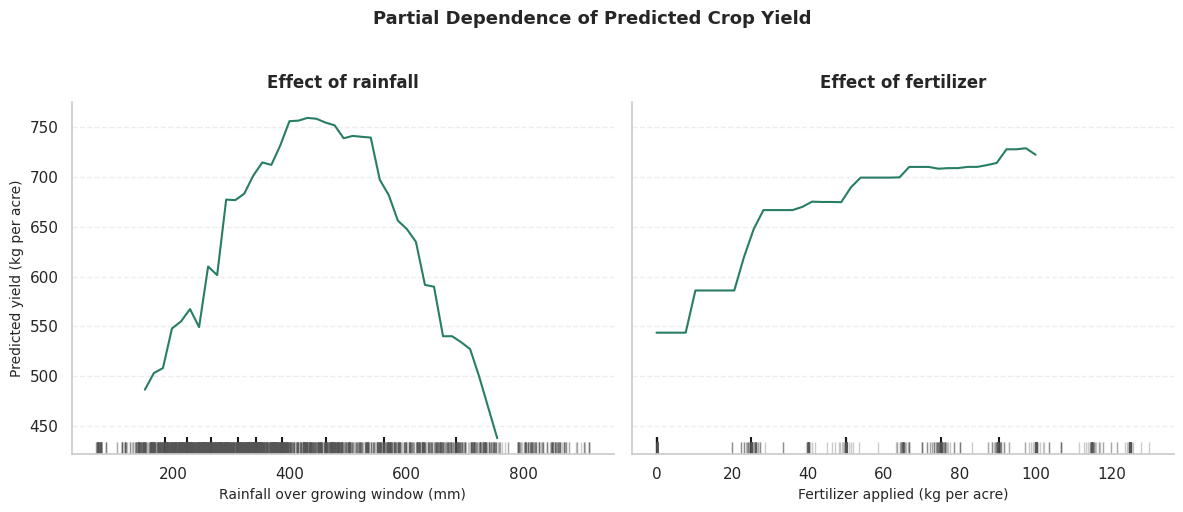

In [34]:
from sklearn.inspection import PartialDependenceDisplay

sns.set_theme(style="whitegrid", context="notebook")

features_to_plot = [
    "season_rain_mm",
    "fertilizer_kg_per_acre"
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharey=True
)

display = PartialDependenceDisplay.from_estimator(
    best_model,
    X_train,
    features_to_plot,
    ax=axes,
    grid_resolution=40,
    line_kw={
        "color": "#287D65",
        "linewidth": 1.5
    }
)

# Customize each panel
labels = [
    "Rainfall over growing window (mm)",
    "Fertilizer applied (kg per acre)"
]

titles = [
    "Effect of rainfall",
    "Effect of fertilizer"
]

for ax, feature, xlabel, title in zip(
    axes, features_to_plot, labels, titles
):
    # Highlight the partial dependence curve
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.grid(axis="x", visible=False)

    # Show the distribution of training observations
    sns.rugplot(
        x=X_train[feature],
        ax=ax,
        height=0.035,
        color="#555555",
        alpha=0.30
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Predicted yield (kg per acre)", fontsize=10)
axes[1].set_ylabel("")

fig.suptitle(
    "Partial Dependence of Predicted Crop Yield",
    fontsize=13,
    fontweight="bold",
    y=1.02
)

fig.tight_layout()
plt.show()

## Save the Results

> The test predictions are written back into DuckDB as marts.yield_predictions, so they can be queried with SQL like everything else.



In [35]:
preds = pd.DataFrame({
    "planting_id": test["planting_id"].values,
    "model": best_name,
    "actual_kg_per_acre": y_test.values,
    "predicted_kg_per_acre": pred_test.round(1),
})
conn.register("preds_df", preds)
conn.sql("CREATE OR REPLACE TABLE marts.yield_predictions AS SELECT * FROM preds_df")
conn.unregister("preds_df")

conn.sql("SELECT COUNT(*) AS predictions_saved FROM marts.yield_predictions").df()

,predictions_saved
0,1455


## Conclusion

> The best model's error is well below the crop-median baseline, so the weather, input and farm features carry real predictive information.

> The importance and partial-dependence charts show the model learned agronomically sensible relationships: a rainfall sweet spot, diminishing returns to fertilizer, and the advantage of certified seed and irrigation.

